In [9]:
from google.colab import files

uploaded = files.upload()

Saving OnlineRetail.csv to OnlineRetail.csv


In [10]:
#PHASE-1: DATA UNDERSTANDING
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [11]:
df = pd.read_csv(
    '/content/OnlineRetail.csv',
    encoding='ISO-8859-1'
)

# First five rows
display(df.head())

# Dataset dimensions
print("Shape:", df.shape)

# Information about columns
df.info()

# Statistical summary
display(df.describe())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [12]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Unique values
print("\nUnique Values:")
print(df.nunique())

# Data types
print("\nData Types:")
print(df.dtypes)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268

Unique Values:
InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [13]:
#PHASE-2: DATA CLEANING AND PREPARATION
retail = df.copy()

# Convert InvoiceDate into datetime
retail['InvoiceDate'] = pd.to_datetime(
    retail['InvoiceDate'],
    errors='coerce'
)

# Remove duplicates
retail = retail.drop_duplicates()

# Remove missing product descriptions
retail = retail.dropna(subset=['Description'])

# Remove invalid dates
retail = retail.dropna(subset=['InvoiceDate'])

# Remove cancelled invoices
retail = retail[
    ~retail['InvoiceNo'].astype(str).str.startswith('C')
]

# Keep positive quantities
retail = retail[retail['Quantity'] > 0]

# Keep positive prices
retail = retail[retail['UnitPrice'] > 0]

# Create Revenue column
retail['Revenue'] = (
    retail['Quantity'] * retail['UnitPrice']
)

print("Original Shape:", df.shape)
print("Cleaned Shape:", retail.shape)

display(retail.head())

Original Shape: (541909, 8)
Cleaned Shape: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [14]:
print("Missing Values:")
print(retail.isnull().sum())

print("\nDuplicates:", retail.duplicated().sum())

print("\nCleaned Dataset Summary:")
display(retail.describe())

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

Duplicates: 0

Cleaned Dataset Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,524878.000000,524878,524878.000000,392692.000000,524878.000000
mean,10.616600,2011-07-04 15:30:16.317049088,3.922573,15287.843865,20.275399
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000,13955.000000,3.900000
50%,4.000000,2011-07-20 11:22:00,2.080000,15150.000000,9.920000
75%,11.000000,2011-10-19 11:41:00,4.130000,16791.000000,17.700000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000,168469.600000
std,156.280031,NaN,36.093028,1713.539549,271.693566


In [15]:
#Create date columns
retail['Year'] = retail['InvoiceDate'].dt.year

retail['Month'] = retail['InvoiceDate'].dt.month

retail['MonthName'] = retail['InvoiceDate'].dt.strftime('%B')

retail['YearMonth'] = retail['InvoiceDate'].dt.to_period('M')

display(retail.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,2010-12


In [16]:
#PHASE-3: EXPLORARTORY DATA ANALYSIS
#Descriptive statistics
numeric_columns = [
    'Quantity',
    'UnitPrice',
    'Revenue'
]

statistics = retail[numeric_columns].agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max'
]).T

statistics['Variance'] = retail[numeric_columns].var()

statistics['Q1'] = retail[numeric_columns].quantile(0.25)

statistics['Q3'] = retail[numeric_columns].quantile(0.75)

statistics['IQR'] = statistics['Q3'] - statistics['Q1']

display(statistics)

,count,mean,median,std,min,max,Variance,Q1,Q3,IQR
Quantity,524878.0,10.616600,4.00,156.280031,1.000,80995.00,24423.448003,1.00,11.00,10.00
UnitPrice,524878.0,3.922573,2.08,36.093028,0.001,13541.33,1302.706636,1.25,4.13,2.88
Revenue,524878.0,20.275399,9.92,271.693566,0.001,168469.60,73817.393968,3.90,17.70,13.80


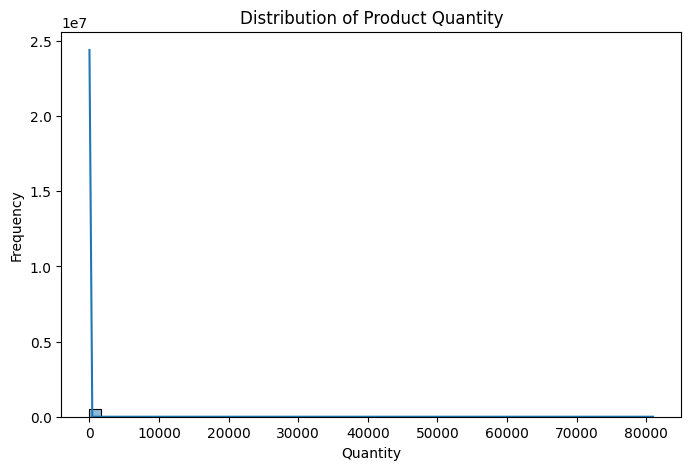

In [17]:
#Quantity distribution
plt.figure(figsize=(8, 5))

sns.histplot(retail['Quantity'], bins=50, kde=True)

plt.title('Distribution of Product Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()

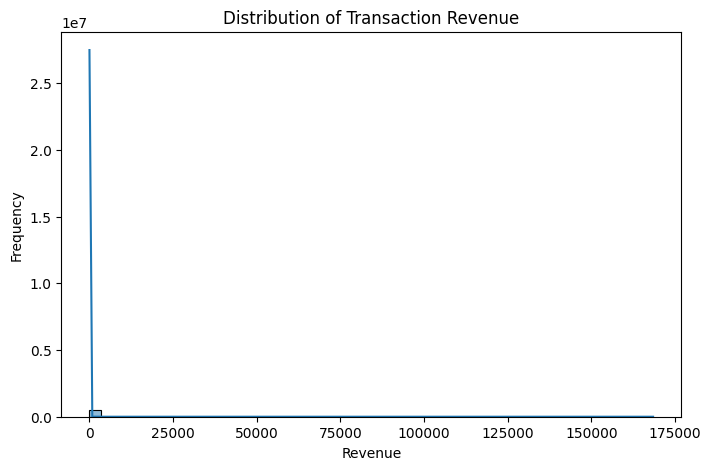

In [18]:
#Revenue distribution
plt.figure(figsize=(8, 5))

sns.histplot(retail['Revenue'], bins=50, kde=True)

plt.title('Distribution of Transaction Revenue')
plt.xlabel('Revenue')
plt.ylabel('Frequency')

plt.show()

In [19]:
#Top 10 best-selling products
product_sales = retail.groupby('Description')['Quantity'].sum()

top_10_products = product_sales.sort_values(
    ascending=False
).head(10)

print("Top 10 Best-Selling Products:")
display(top_10_products)

Top 10 Best-Selling Products:


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


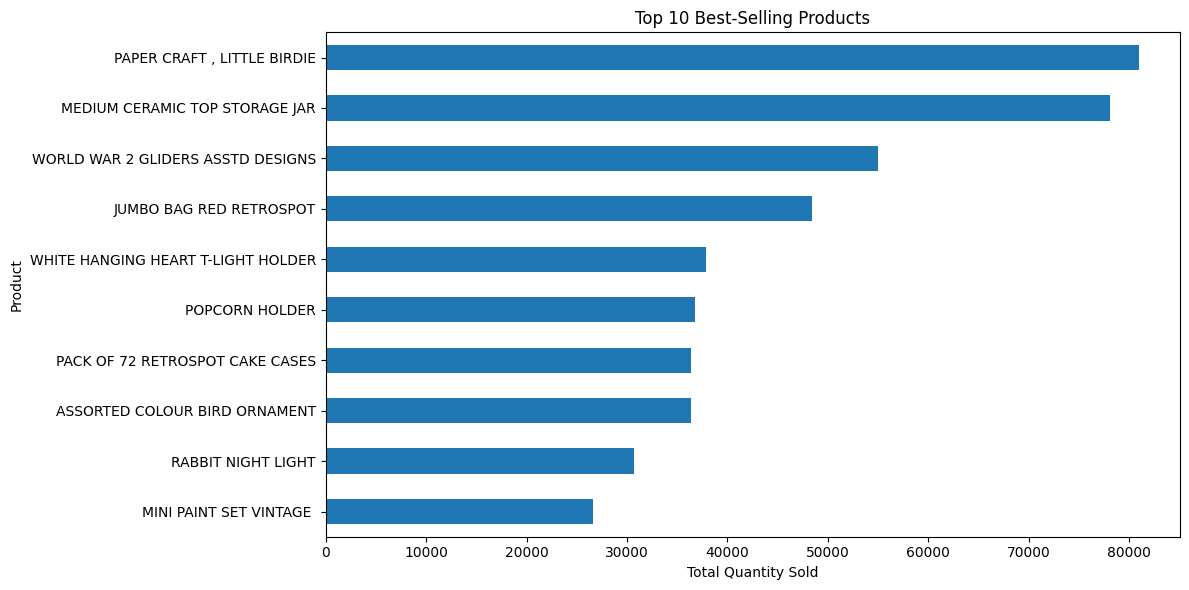

In [20]:
#Visualise best-selling products
plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [21]:
#Top 10 products by revenue
product_revenue = retail.groupby('Description')['Revenue'].sum()

top_10_revenue = product_revenue.sort_values(
    ascending=False
).head(10)

print("Top 10 Products by Revenue:")
display(top_10_revenue)

Top 10 Products by Revenue:


,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


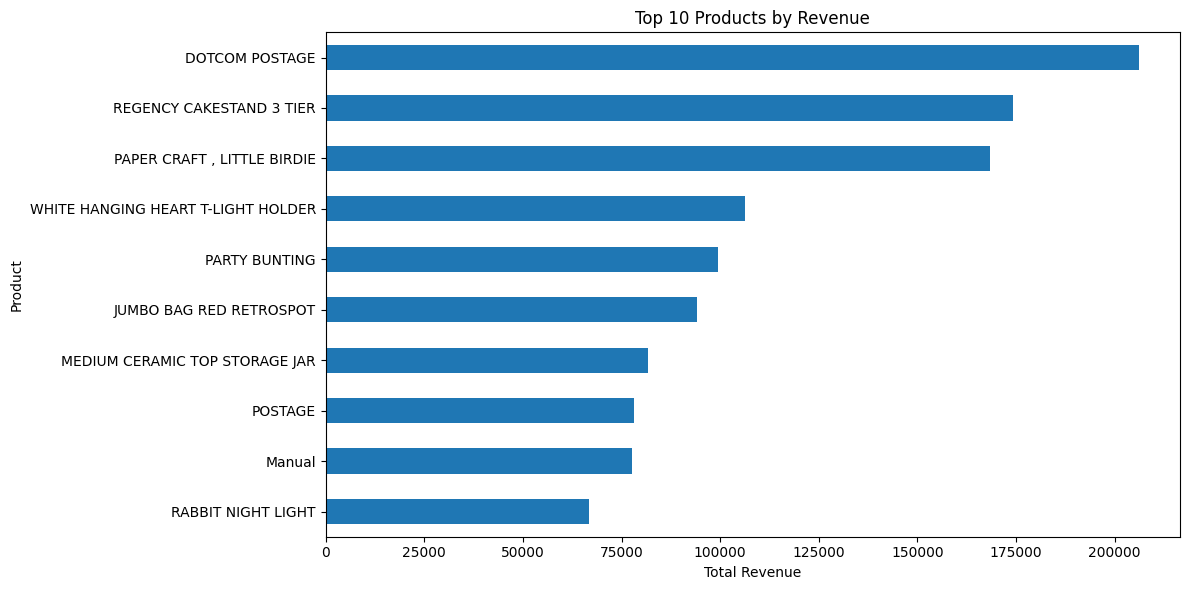

In [22]:
plt.figure(figsize=(12, 6))

top_10_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [23]:
#Monthly sales analysis
monthly_sales = retail.groupby('YearMonth')['Revenue'].sum()

display(monthly_sales)

,Revenue
YearMonth,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


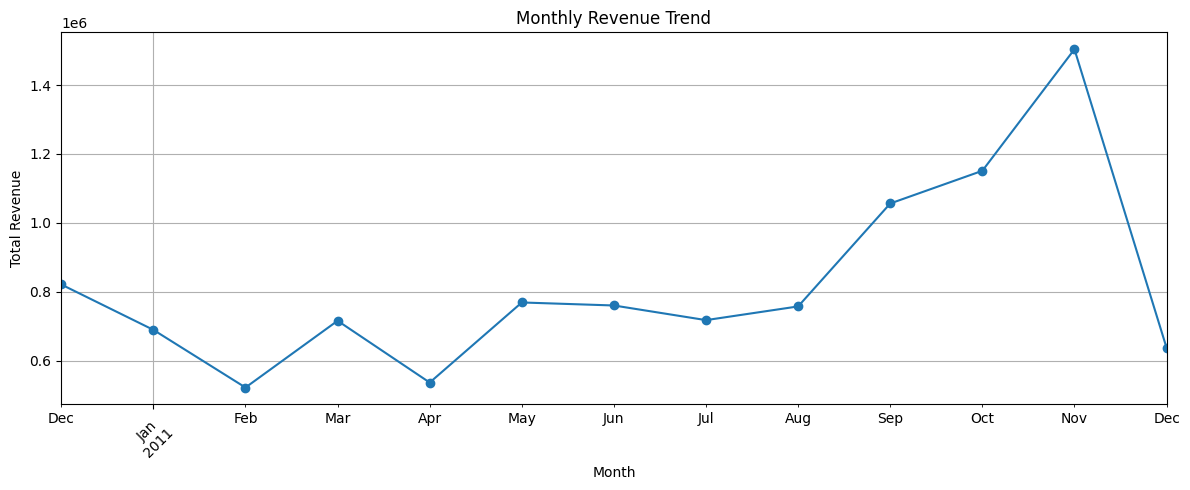

In [24]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
#Country-wise sales analysis
country_sales = retail.groupby('Country')['Revenue'].sum()

top_10_countries = country_sales.sort_values(
    ascending=False
).head(10)

display(top_10_countries)

,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


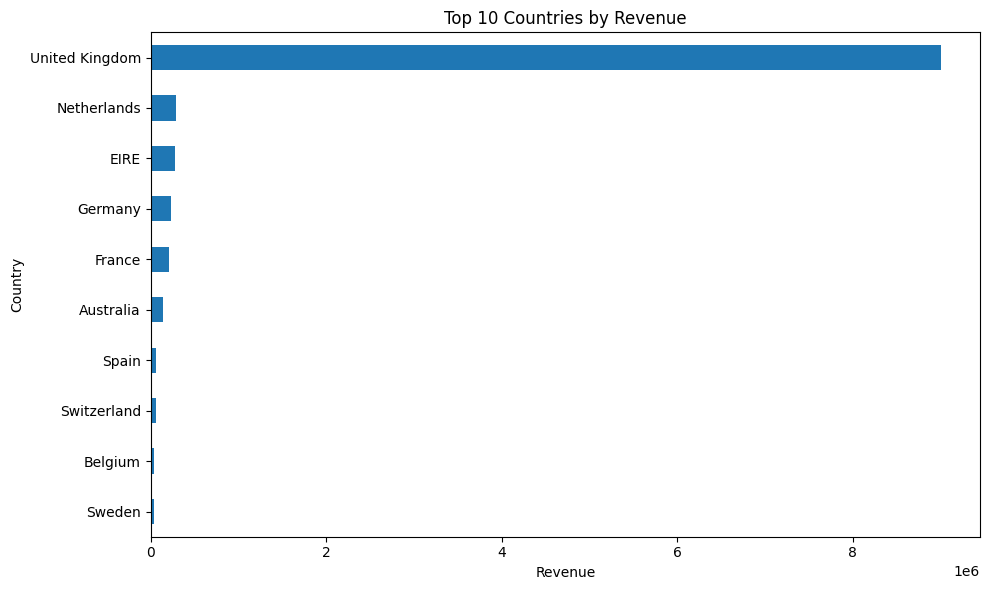

In [26]:
plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [27]:
#PHASE-4: RELATIONSHIPS BETWEEN VARIABLES

correlation_matrix = retail[
    ['Quantity', 'UnitPrice', 'Revenue']
].corr(method='pearson')

display(correlation_matrix)

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.003788,0.907402
UnitPrice,-0.003788,1.000000,0.137381
Revenue,0.907402,0.137381,1.000000


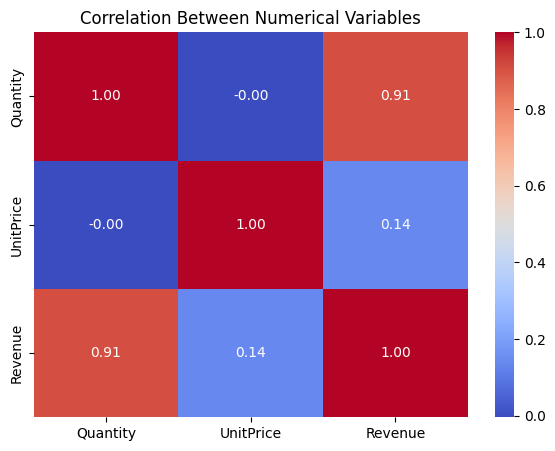

In [28]:
#Correlation heatmap

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Variables')

plt.show()

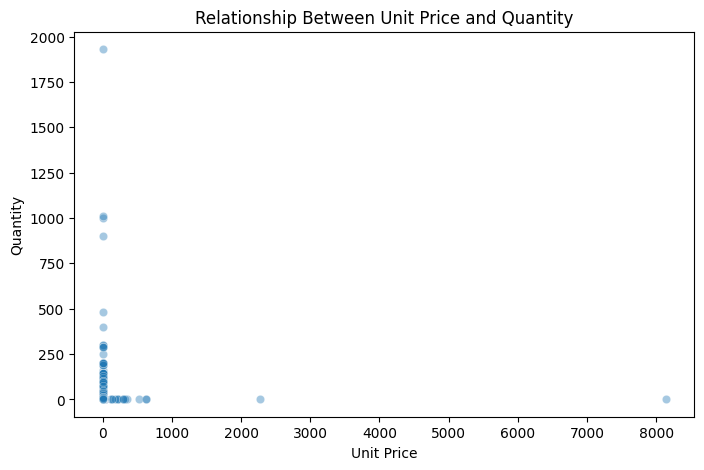

In [29]:
#Scatter plot: Quantity vs Unit Price

sample_data = retail.sample(
    n=min(5000, len(retail)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_data,
    x='UnitPrice',
    y='Quantity',
    alpha=0.4
)

plt.title('Relationship Between Unit Price and Quantity')
plt.xlabel('Unit Price')
plt.ylabel('Quantity')

plt.show()

In [30]:
#Compare quantities across countries

top_countries = retail['Country'].value_counts().head(5).index

country_comparison = retail[
    retail['Country'].isin(top_countries)
].groupby('Country')['Quantity'].agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max'
])

display(country_comparison)

,count,mean,median,std,min,max
Country,,,,,,
EIRE,7879,18.658078,12.0,39.900461,1,1440
France,8392,13.353194,10.0,21.084032,1,912
Germany,9025,13.202659,10.0,17.652026,1,600
Spain,2479,11.267850,6.0,22.852442,1,360
United Kingdom,479985,9.681357,3.0,162.751675,1,80995


In [31]:
#Monthly revenue growth

monthly_comparison = monthly_sales.to_frame(
    name='Revenue'
)

monthly_comparison['Previous_Month_Revenue'] = (
    monthly_comparison['Revenue'].shift(1)
)

monthly_comparison['Revenue_Change'] = (
    monthly_comparison['Revenue'] -
    monthly_comparison['Previous_Month_Revenue']
)

monthly_comparison['Growth_Percentage'] = (
    monthly_comparison['Revenue_Change'] /
    monthly_comparison['Previous_Month_Revenue']
) * 100

display(monthly_comparison)

,Revenue,Previous_Month_Revenue,Revenue_Change,Growth_Percentage
YearMonth,,,,
2010-12,821452.730,NaN,NaN,NaN
2011-01,689811.610,821452.730,-131641.120,-16.025404
2011-02,522545.560,689811.610,-167266.050,-24.248077
2011-03,716215.260,522545.560,193669.700,37.062740
2011-04,536968.491,716215.260,-179246.769,-25.026941
2011-05,769296.610,536968.491,232328.119,43.266620
2011-06,760547.010,769296.610,-8749.600,-1.137351
2011-07,718076.121,760547.010,-42470.889,-5.584256
2011-08,757841.380,718076.121,39765.259,5.537750


In [32]:
#PHASE-5: FINDINGS AND CONCLUSION
#Generate project findings

best_product = product_sales.idxmax()

best_quantity = product_sales.max()

highest_revenue_product = product_revenue.idxmax()

highest_revenue = product_revenue.max()

best_month = monthly_sales.idxmax()

best_country = country_sales.idxmax()

print("PROJECT FINDINGS")
print("--------------------------")

print("Best-Selling Product:", best_product)
print("Total Quantity Sold:", best_quantity)

print("\nHighest Revenue Product:", highest_revenue_product)
print("Revenue Generated:", highest_revenue)

print("\nMonth with Highest Revenue:", best_month)

print("\nCountry with Highest Revenue:", best_country)

PROJECT FINDINGS
--------------------------
Best-Selling Product: PAPER CRAFT , LITTLE BIRDIE
Total Quantity Sold: 80995

Highest Revenue Product: DOTCOM POSTAGE
Revenue Generated: 206248.77

Month with Highest Revenue: 2011-11

Country with Highest Revenue: United Kingdom


In [33]:
#Export results

# Save cleaned dataset
retail.to_csv('Cleaned_OnlineRetail.csv', index=False)

# Create product summary
product_summary = retail.groupby('Description').agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('Revenue', 'sum'),
    Average_Unit_Price=('UnitPrice', 'mean')
)

product_summary = product_summary.sort_values(
    by='Total_Quantity',
    ascending=False
)

product_summary.to_csv('Product_Sales_Summary.csv')

print("Files saved successfully!")

Files saved successfully!
